# Page 16 — Persian Newspaper Archive
## Exploratory Data Analysis & Evidence-Based Design Recommendations

**Presentation scope:** three supplied PDF files, 28 pages; no labeled ground truth.

**Central question:** What does this sample tell us about a CPU-only pipeline that reconstructs complete newspaper articles?

**Reading guide**
1. Corpus inventory and text-layer availability
2. Page heterogeneity, layout geometry and image resolution
3. Continuation markers and concrete extraction failures
4. Runtime observations and the limits of the evidence
5. Proposed solutions, validation experiments and delivery priorities

> **Evidence policy:** measured results are calculated from the EDA exports. Visual observations are explicitly identified. Design proposals are hypotheses to validate. PDF blocks are not article annotations, and text availability is not text accuracy.

## 1. Reproducibility and data lineage

This notebook reads the exports created by `eda.py`; it does not silently rerun extraction or change the original PDFs. Raw text, bounding boxes, image placements and file hashes remain available for audit.

**Setup:** `python -m pip install -r requirements-notebook.txt`.

If exports are missing, first run the `eda.py analyze ... --output outputs` command in `README.md`. Keep the notebook beside `outputs/`, or change `OUTPUT_DIR` below. All plots and insight text are regenerated from the loaded tables.

**Units:** geometry in unrotated PDF points (72 points/inch); effective image DPI from placement transforms; runtime in seconds; RSS in MiB despite the export field's `mb` suffix.

In [1]:
from pathlib import Path
import json
import math
import platform
import re
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

OUTPUT_DIR = Path('outputs')
if not (OUTPUT_DIR / 'summary.json').exists():
    raise FileNotFoundError('EDA exports are missing. Run eda.py analyze first or update OUTPUT_DIR.')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 12, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 90)
COLORS = {'1-7.pdf': '#3977b8', '1-8.pdf': '#e38932', '1-9.pdf': '#409c79'}

def load_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

summaries = load_json(OUTPUT_DIR / 'summary.json')
environment = load_json(OUTPUT_DIR / 'environment.json')
directories = {Path(s['source_file']).name: OUTPUT_DIR / s['directory'] for s in summaries}

def read_issue_table(filename, json_file=False):
    frames = []
    for file, directory in directories.items():
        frame = pd.DataFrame(load_json(directory / filename)) if json_file else pd.read_csv(directory / filename)
        frame['file'] = file
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)

pages = read_issue_table('pages.json', json_file=True)
images = read_issue_table('images.csv')
markers = read_issue_table('markers.json', json_file=True)
fonts = read_issue_table('fonts.csv')
inventory = pd.DataFrame(summaries)
inventory['file'] = inventory['source_file'].map(lambda p: Path(p).name)
pages['label'] = pages['file'] + ' / p' + pages['pdf_page'].astype(str)
pages['chars_per_block'] = pages['characters'] / pages['text_blocks'].replace(0, np.nan)
pages['chars_per_line'] = pages['characters'] / pages['text_lines'].replace(0, np.nan)

# Provenance and minimal consistency checks.
assert not pages.duplicated(['file', 'pdf_page']).any()
assert pages['pdf_page'].ge(1).all()
assert pages['text_bbox_coverage_approx'].between(0, 1).all()
assert pages['image_bbox_coverage_approx'].between(0, 1).all()
assert inventory['page_count'].sum() == len(pages)
display(pd.DataFrame([{'Export timestamp (UTC)': environment['timestamp_utc'],
                      'Extraction Python': environment['python'], 'PyMuPDF': environment['pymupdf'],
                      'Physical / logical cores': f"{environment['physical_cores']} / {environment['logical_cores']}",
                      'System RAM (GiB)': round(environment['ram_gb'], 1),
                      'Notebook Python': platform.python_version()}]))
display(inventory[['file', 'page_count', 'sha256']])

,Export timestamp (UTC),Extraction Python,PyMuPDF,Physical / logical cores,System RAM (GiB),Notebook Python
0,2026-10-07T16:22:20Z,3.13.5,1.27.2.2,2 / 4,3.9,3.13.5


,file,page_count,sha256
0,1-7.pdf,8,b386efd92538f39515f10f9e002af625f0d847508c5810a599b34d630ffa988d
1,1-8.pdf,16,4ddf204f581bd94a0dee14df992a8c4e5580e7c5be8673af6cc46fa124853f44
2,1-9.pdf,4,94476d67682c5c319bedbc1e3201a66c84a19a0ad305f4ac2200a30e1f7aa0f4


## 2. Corpus inventory — what is actually available?

Count extracted characters before attempting to infer OCR needs. Character counts include whitespace and may include duplicate PDF text objects; they are **not counts of correct, unique printed characters**.

,pages,characters,median_chars_per_page,min_chars_per_page,max_chars_per_page,text_blocks,text_lines,image_placements,detected_markers
file,,,,,,,,,
1-7.pdf,8,140827,19276.0,3402,21663,362,3279,60,0
1-8.pdf,16,363281,23149.0,12178,29146,1309,8862,169,6
1-9.pdf,4,69461,19203.5,10545,20509,131,1306,54,0


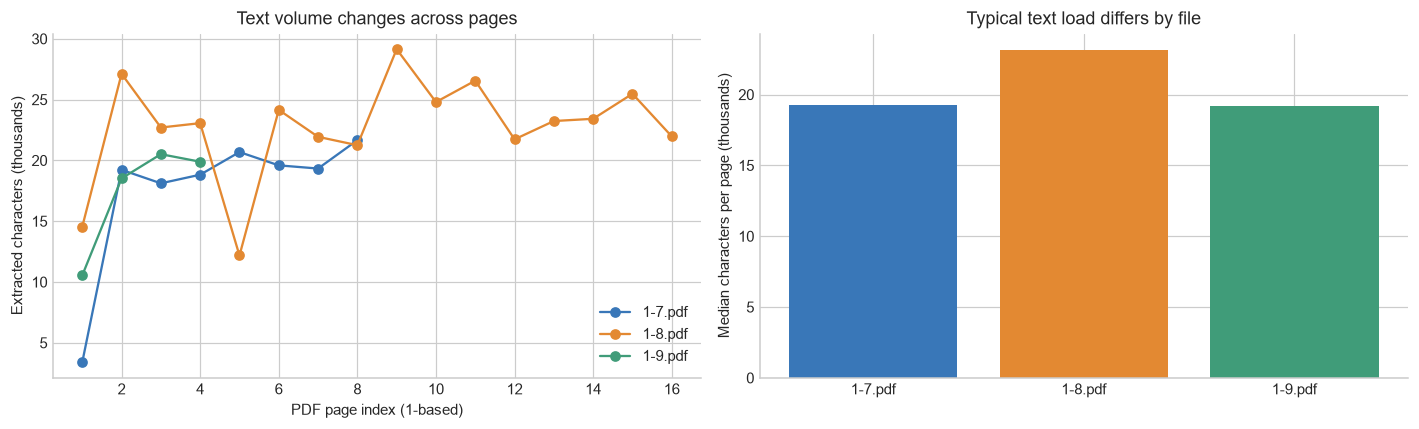

**Measured insight:** 28/28 pages contain at least 50 non-whitespace extracted characters.
The sample contains 573,569 extracted characters in total.
**Implication:** test a PDF-text-first route before spending CPU on full-page OCR.
**Boundary:** these three files provide no demonstrated text-free benchmark; performance on a scanned-only archive remains unknown.

In [2]:
corpus = pages.groupby('file').agg(
    pages=('pdf_page', 'count'), characters=('characters', 'sum'),
    median_chars_per_page=('characters', 'median'),
    min_chars_per_page=('characters', 'min'), max_chars_per_page=('characters', 'max'),
    text_blocks=('text_blocks', 'sum'), text_lines=('text_lines', 'sum'),
    image_placements=('image_placements', 'sum'), detected_markers=('continuation_markers', 'sum'))
display(corpus.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for file, group in pages.groupby('file', sort=True):
    axes[0].plot(group['pdf_page'], group['characters'] / 1000, marker='o', label=file, color=COLORS[file])
axes[0].set(xlabel='PDF page index (1-based)', ylabel='Extracted characters (thousands)', title='Text volume changes across pages')
axes[0].legend()
axes[1].bar(corpus.index, corpus['median_chars_per_page'] / 1000, color=[COLORS[f] for f in corpus.index])
axes[1].set(ylabel='Median characters per page (thousands)', title='Typical text load differs by file')
plt.tight_layout()
plt.show()

available = pages['nonspace_characters'].ge(50).sum()
display(Markdown(f'''**Measured insight:** {available}/{len(pages)} pages contain at least 50 non-whitespace extracted characters.
The sample contains {int(pages['characters'].sum()):,} extracted characters in total.
**Implication:** test a PDF-text-first route before spending CPU on full-page OCR.
**Boundary:** these three files provide no demonstrated text-free benchmark; performance on a scanned-only archive remains unknown.'''))

## 3. Text-layer triage is not an accuracy score

The extractor flags pages using a small-text threshold, suspicious Unicode characters and Arabic-script character share. These features detect some failures but cannot catch all wrong glyph mappings, duplicated text or column-order errors.

The Arabic-script ratio is calculated over non-whitespace characters and is **not a Persian-language probability**. Low ZWNJ counts are also not proof of missing half-spaces without a reference transcript.

text_layer_triage,text_present_needs_gold_check
file,
1-7.pdf,8
1-8.pdf,16
1-9.pdf,4


,median_arabic_script_share,max_suspicious_character_share,replacement_characters,zwnj_count
file,,,,
1-7.pdf,0.9720,0.0,0,26
1-8.pdf,0.9116,0.0,0,2649
1-9.pdf,0.9641,0.0,0,0


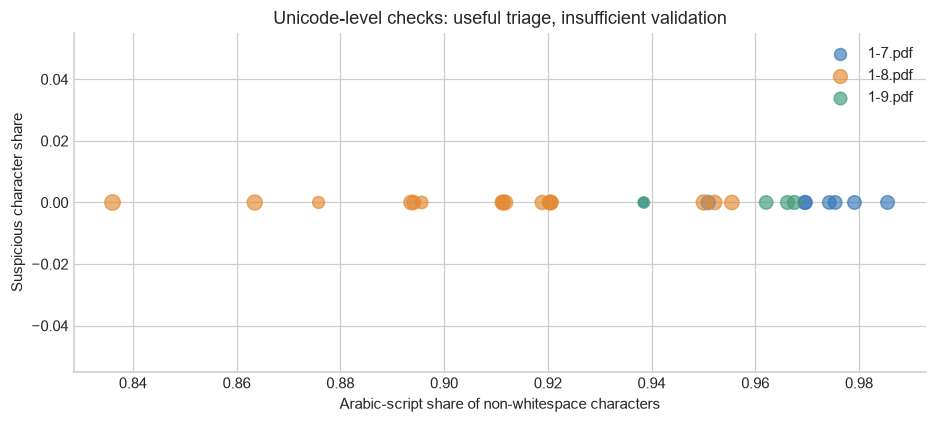

**Key distinction:** a clean Unicode score can coexist with a visibly incorrect continuation number. Section 7 shows an actual example from this corpus.

In [3]:
display(pd.crosstab(pages['file'], pages['text_layer_triage']))
quality = pages.groupby('file').agg(
    median_arabic_script_share=('arabic_script_ratio', 'median'),
    max_suspicious_character_share=('suspicious_character_ratio', 'max'),
    replacement_characters=('replacement_characters', 'sum'), zwnj_count=('zwnj_count', 'sum'))
display(quality.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
for file, group in pages.groupby('file'):
    ax.scatter(group['arabic_script_ratio'], group['suspicious_character_ratio'],
               s=30 + group['characters']/400, alpha=.65, label=file, color=COLORS[file])
ax.set(xlabel='Arabic-script share of non-whitespace characters', ylabel='Suspicious character share',
       title='Unicode-level checks: useful triage, insufficient validation')
ax.legend()
plt.show()
display(Markdown('**Key distinction:** a clean Unicode score can coexist with a visibly incorrect continuation number. Section 7 shows an actual example from this corpus.'))

## 4. Page heterogeneity — one layout rule will not fit every page

Text/image coverage measures the **union of bounding boxes on an approximate grid**, not ink area. Text and image coverage can overlap, so they should not be added as if they were mutually exclusive classes.

Large variation in blocks, text volume and image coverage is evidence of different processing loads. It does not, by itself, identify advertisements or prove semantic segmentation difficulty.

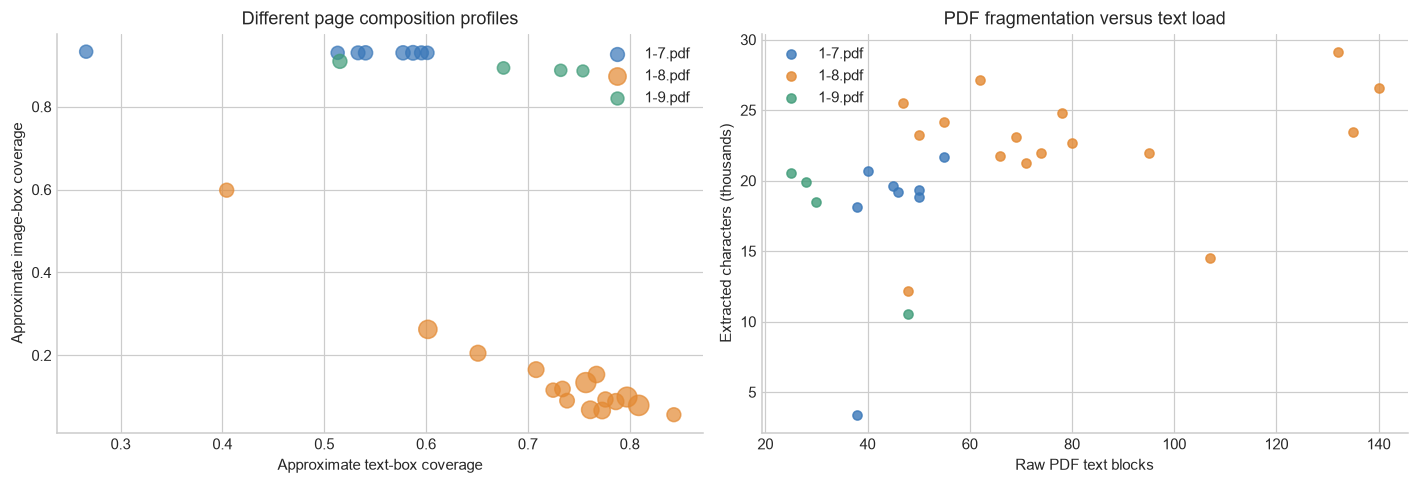

,chars_mean,chars_std,blocks_min,blocks_max,image_coverage_min,image_coverage_max,character_cv
file,,,,,,,
1-7.pdf,17603.375,5842.496,38,55,0.930,0.933,0.332
1-8.pdf,22705.062,4261.640,47,140,0.057,0.598,0.188
1-9.pdf,17365.250,4622.305,25,48,0.886,0.909,0.266


,file,pdf_page,characters,text_blocks,text_lines,image_bbox_coverage_approx
18,1-8.pdf,11,26556,140,756,0.0792
21,1-8.pdf,14,23420,135,671,0.1342
16,1-8.pdf,9,29146,132,898,0.0992
8,1-8.pdf,1,14549,107,317,0.2626
23,1-8.pdf,16,21970,95,496,0.0685
10,1-8.pdf,3,22702,80,534,0.0667


**Design implication:** stratify annotation and evaluation by page composition (front page, dense interior, image-heavy, classified/advertisement). A detector must be justified against a geometric baseline on these strata, not only on an aggregate score.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for file, group in pages.groupby('file'):
    axes[0].scatter(group['text_bbox_coverage_approx'], group['image_bbox_coverage_approx'],
                    s=35 + group['text_blocks'], alpha=.7, label=file, color=COLORS[file])
    axes[1].scatter(group['text_blocks'], group['characters']/1000, label=file, color=COLORS[file], alpha=.8)
axes[0].set(xlabel='Approximate text-box coverage', ylabel='Approximate image-box coverage',
            title='Different page composition profiles')
axes[1].set(xlabel='Raw PDF text blocks', ylabel='Extracted characters (thousands)',
            title='PDF fragmentation versus text load')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

variation = pages.groupby('file').agg(
    chars_mean=('characters', 'mean'), chars_std=('characters', 'std'),
    blocks_min=('text_blocks', 'min'), blocks_max=('text_blocks', 'max'),
    image_coverage_min=('image_bbox_coverage_approx', 'min'),
    image_coverage_max=('image_bbox_coverage_approx', 'max'))
variation['character_cv'] = variation['chars_std'] / variation['chars_mean']
display(variation.round(3))
display(pages.nlargest(6, 'text_blocks')[['file', 'pdf_page', 'characters', 'text_blocks', 'text_lines', 'image_bbox_coverage_approx']])
display(Markdown('**Design implication:** stratify annotation and evaluation by page composition (front page, dense interior, image-heavy, classified/advertisement). A detector must be justified against a geometric baseline on these strata, not only on an aggregate score.'))

## 5. Visual evidence — inspect the page, not only its counts

The next contact sheet uses actual exported overlays. **Blue = raw PDF text block; red = block with a detected continuation marker; orange = image placement.** PDF blocks have not been labeled as title, article body or advertisement.

For presentation, zoom into the original images in `outputs/` to inspect individual block IDs. These thumbnails illustrate page composition rather than character legibility.

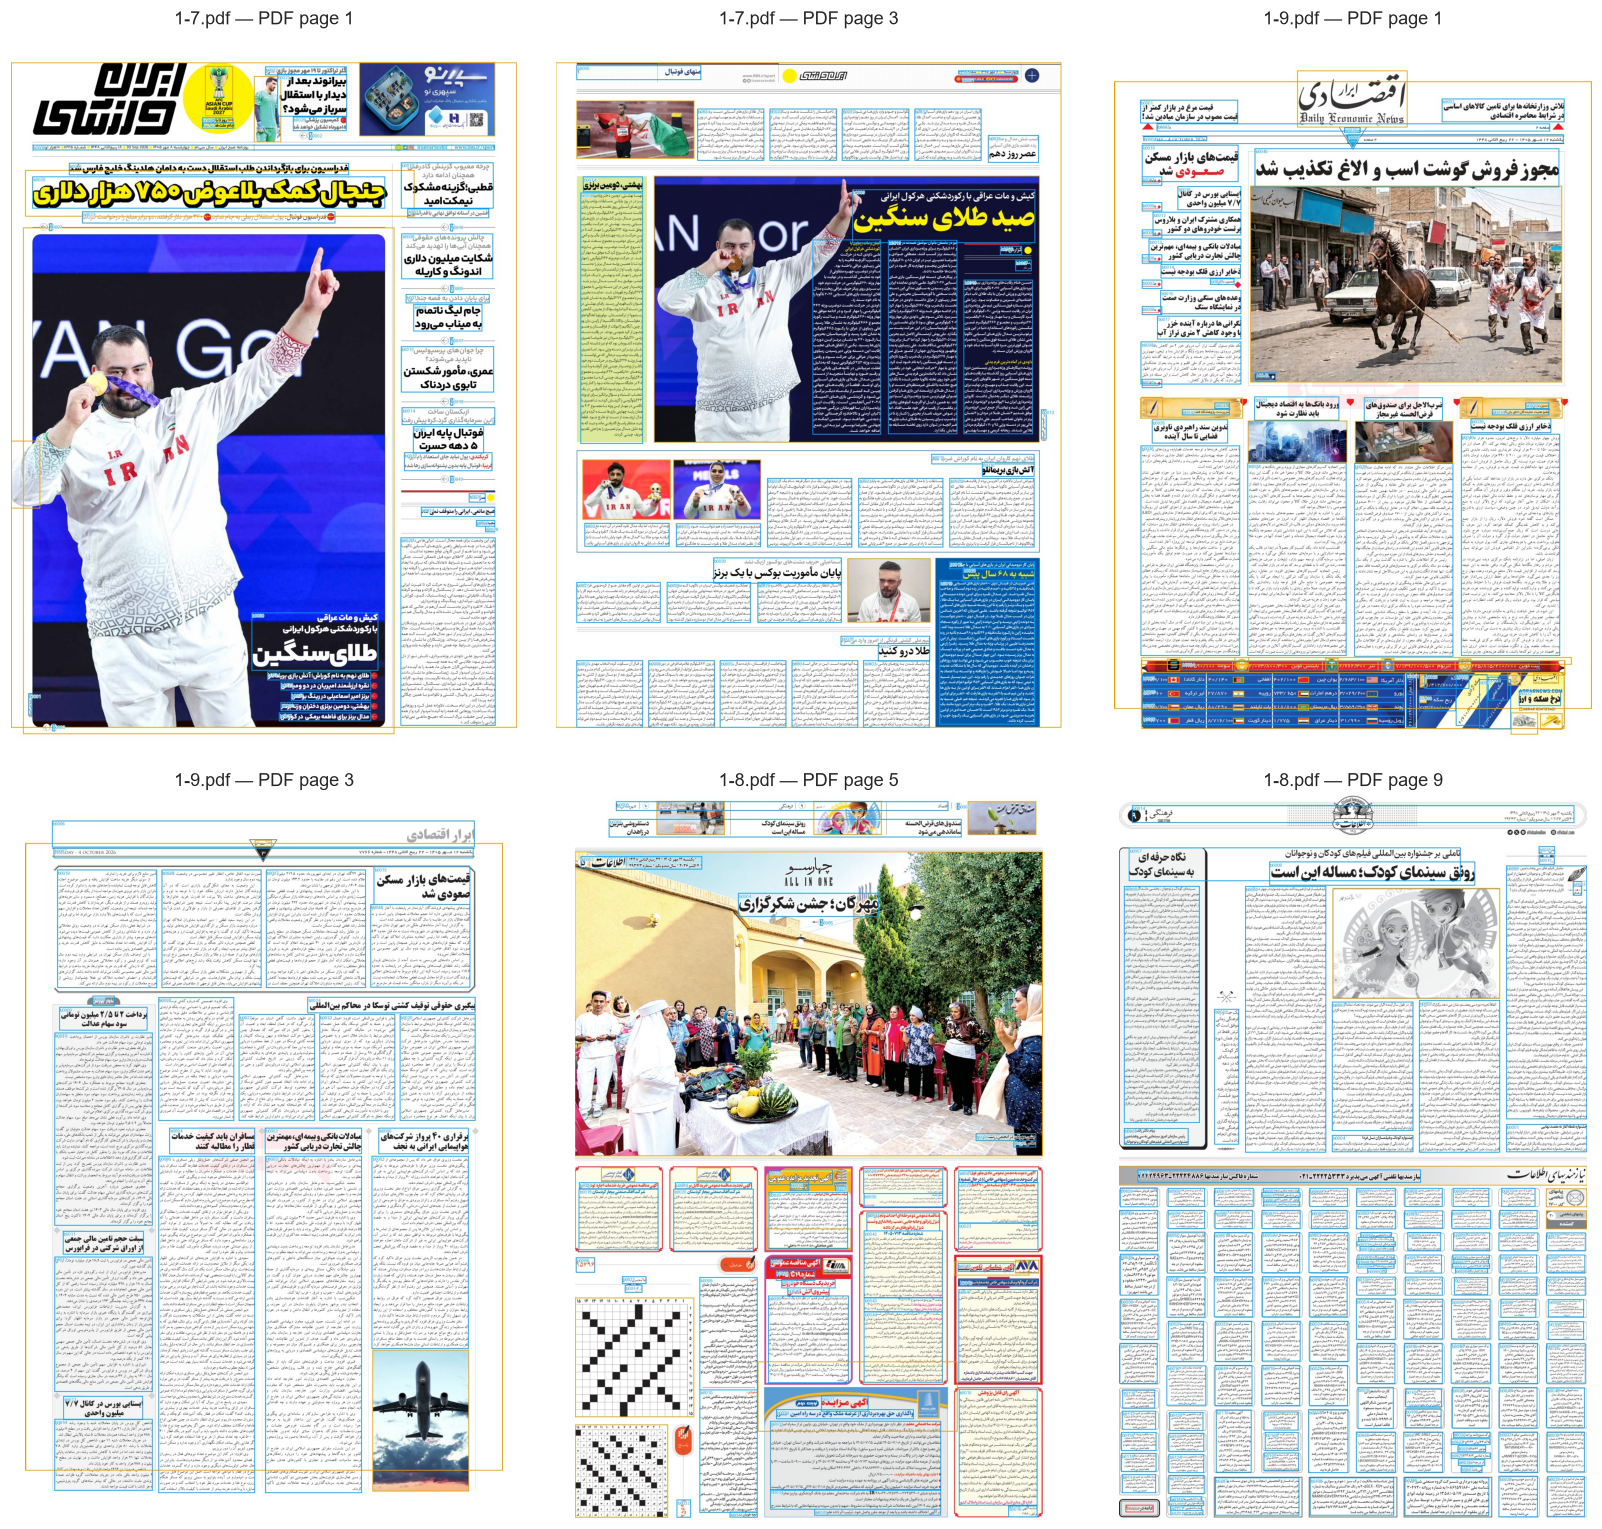

In [5]:
def show_pages(selections, columns=3, overlay=True):
    rows = math.ceil(len(selections)/columns)
    fig, axes = plt.subplots(rows, columns, figsize=(5*columns, 7*rows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (file, number) in zip(axes.flat, selections):
        name = 'overlay.jpg' if overlay else 'page.jpg'
        path = directories[file] / f'page-{number:03d}' / name
        if path.exists():
            with Image.open(path) as image:
                ax.imshow(image.copy())
        else:
            ax.text(.1, .5, 'Render missing; rerun without --no-render', transform=ax.transAxes)
        ax.set_title(f'{file} — PDF page {number}')
    plt.tight_layout()
    plt.show()

show_pages([('1-7.pdf', 1), ('1-7.pdf', 3), ('1-9.pdf', 1),
            ('1-9.pdf', 3), ('1-8.pdf', 5), ('1-8.pdf', 9)])

### Visual observations to discuss during the presentation

- **`1-7.pdf`, page 3:** a large image coexists with text regions and smaller neighboring items. Global top-to-bottom sorting can mix independent content; local article grouping must precede final reading order.
- **`1-9.pdf`, pages 1 and 3:** multiple content regions share similar vertical positions. A global right-to-left sort is insufficient to recover article boundaries.
- **`1-8.pdf`, pages 5 and 9:** page composition changes substantially. Regions that look like advertisements/classifieds, tables or captions require human-confirmed semantic labels before being included in editorial articles.

These are **visual observations**, not measured detector accuracy. The next dataset should explicitly annotate content type and article membership.

## 6. Embedded images and effective resolution

Image records represent **placements**, not unique assets. A large background image may coexist with selectable text. Presence of such an image does not justify full-page OCR if an accurate text layer can be recovered.

Below, minimum axis DPI is a conservative resolution summary. The 150/300 DPI lines are reference values for comparison, not OCR acceptance thresholds.

,placements,dpi_p10,dpi_median,dpi_p90,large_placements
file,,,,,
1-7.pdf,60,100.1,109.2,300.0,8
1-8.pdf,169,72.0,300.1,346.9,0
1-9.pdf,54,139.2,149.0,150.1,4


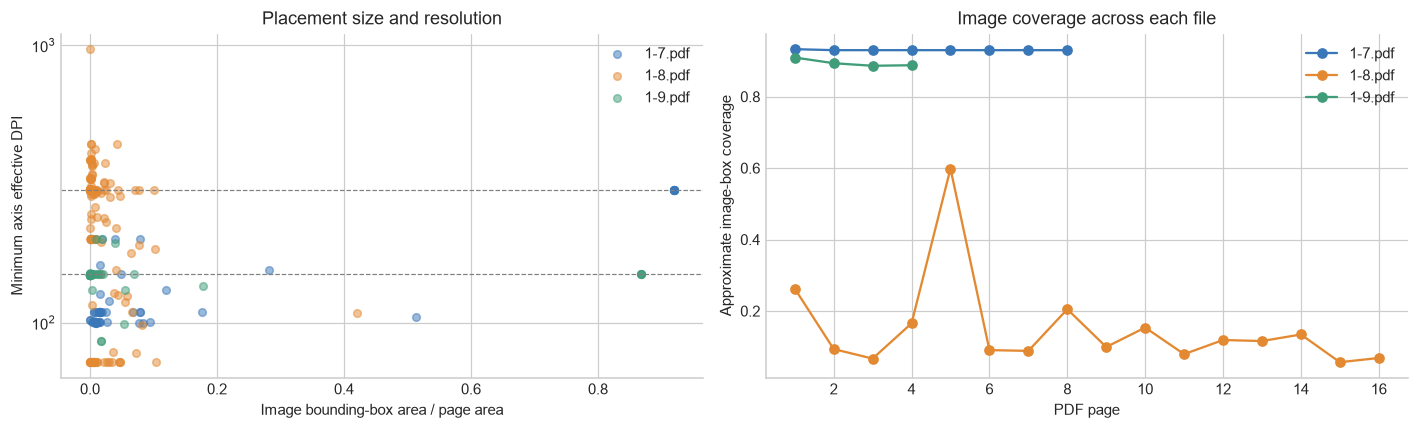

,file,pdf_page,width_px,height_px,effective_dpi_x,effective_dpi_y,area_fraction_bbox
0,1-7.pdf,1,4133,5433,300.0,300.0,0.92
9,1-7.pdf,2,4133,5433,300.0,300.0,0.92
14,1-7.pdf,3,4133,5433,300.0,300.0,0.92
20,1-7.pdf,4,4133,5433,300.0,300.0,0.92
28,1-7.pdf,5,4133,5433,300.0,300.0,0.92
33,1-7.pdf,6,4133,5433,300.0,300.0,0.92
41,1-7.pdf,7,4133,5433,300.0,300.0,0.92
53,1-7.pdf,8,4133,5433,300.0,300.0,0.92


**Proposed action:** separate low-resolution layout previews from high-resolution OCR crops. Test native images versus PDF renders; upsampling does not recreate missing source detail. Report OCR error by text size and scan quality, rather than DPI alone.

In [6]:
images['min_axis_dpi'] = images[['effective_dpi_x', 'effective_dpi_y']].min(axis=1)
valid_images = images.loc[images['min_axis_dpi'].gt(0)].copy()
display(valid_images.groupby('file').agg(
    placements=('image_id', 'count'), dpi_p10=('min_axis_dpi', lambda x: x.quantile(.1)),
    dpi_median=('min_axis_dpi', 'median'), dpi_p90=('min_axis_dpi', lambda x: x.quantile(.9)),
    large_placements=('area_fraction_bbox', lambda x: (x >= .7).sum())).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for file, group in valid_images.groupby('file'):
    axes[0].scatter(group['area_fraction_bbox'], group['min_axis_dpi'], alpha=.5, s=25,
                    color=COLORS[file], label=file)
axes[0].set(xlabel='Image bounding-box area / page area', ylabel='Minimum axis effective DPI',
            title='Placement size and resolution', yscale='log')
for value in (150, 300):
    axes[0].axhline(value, color='grey', lw=.8, linestyle='--')
axes[0].legend()
for file, group in pages.groupby('file'):
    axes[1].plot(group['pdf_page'], group['image_bbox_coverage_approx'], marker='o', color=COLORS[file], label=file)
axes[1].set(xlabel='PDF page', ylabel='Approximate image-box coverage', title='Image coverage across each file')
axes[1].legend()
plt.tight_layout()
plt.show()

display(valid_images.nlargest(8, 'area_fraction_bbox')[['file', 'pdf_page', 'width_px', 'height_px',
                                                     'effective_dpi_x', 'effective_dpi_y', 'area_fraction_bbox']].round(2))
display(Markdown('**Proposed action:** separate low-resolution layout previews from high-resolution OCR crops. Test native images versus PDF renders; upsampling does not recreate missing source detail. Report OCR error by text size and scan quality, rather than DPI alone.'))

## 7. Continuation markers — a small but decisive failure case

Marker recall is unknown: only regex-detected cases are available. Zero detections in a file must not be interpreted as zero continuations.

The parser retains raw text and distinguishes definite parsed numbers from number candidates requiring review. All detected markers still require editorial/advertisement classification.

,file,pdf_page,direction,page_token,referenced_printed_page,number_candidates_needs_review,extraction_pattern,block_text_raw
0,1-8.pdf,2.0,to,1414,NaN,[14],preceding_number_needs_review,1414 بقیه در صفحه بقیه در صفحه
1,1-8.pdf,2.0,to,1414,NaN,[14],preceding_number_needs_review,1414 بقیه در صفحه\n بقیه در صفحه
2,1-8.pdf,9.0,to,11,11.0,[],preceding_number_needs_review,11 ادامه در صفحه
3,1-8.pdf,11.0,from,9,9.0,[],preceding_number_needs_review,9 ادامه از صفحه
4,1-8.pdf,14.0,from,2,2.0,[],preceding_number_needs_review,2 بقیه از صفحه\n بقیه از صفحه
5,1-8.pdf,14.0,from,2,2.0,[],preceding_number_needs_review,2 بقیه از صفحه\n بقیه از صفحه


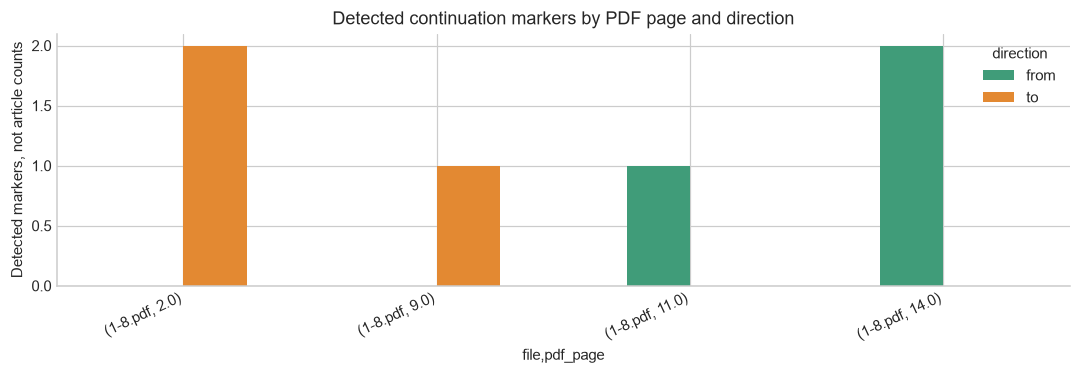

**Measured insight:** 6 markers were detected; 2 have candidate-only numbers.
    The duplicated token `1414` is retained as raw evidence; `14` is a hypothesis, not an automatic correction.
    **Implication:** continuation extraction needs span/geometry-aware checks and a review state, even when the text layer passes Unicode triage.

In [7]:
if markers.empty:
    display(Markdown('No markers detected. Inspect rendered pages before drawing conclusions.'))
else:
    display(markers[['file', 'pdf_page', 'direction', 'page_token', 'referenced_printed_page',
                     'number_candidates_needs_review', 'extraction_pattern', 'block_text_raw']])
    marker_counts = markers.groupby(['file', 'pdf_page', 'direction']).size().unstack(fill_value=0)
    marker_counts.plot.bar(figsize=(10, 3.5), color=['#409c79', '#e38932'])
    plt.title('Detected continuation markers by PDF page and direction')
    plt.ylabel('Detected markers, not article counts')
    plt.xticks(rotation=25, ha='right')
    plt.tight_layout()
    plt.show()
    ambiguous = markers['number_candidates_needs_review'].map(bool).sum()
    display(Markdown(f'''**Measured insight:** {len(markers)} markers were detected; {ambiguous} have candidate-only numbers.
    The duplicated token `1414` is retained as raw evidence; `14` is a hypothesis, not an automatic correction.
    **Implication:** continuation extraction needs span/geometry-aware checks and a review state, even when the text layer passes Unicode triage.'''))

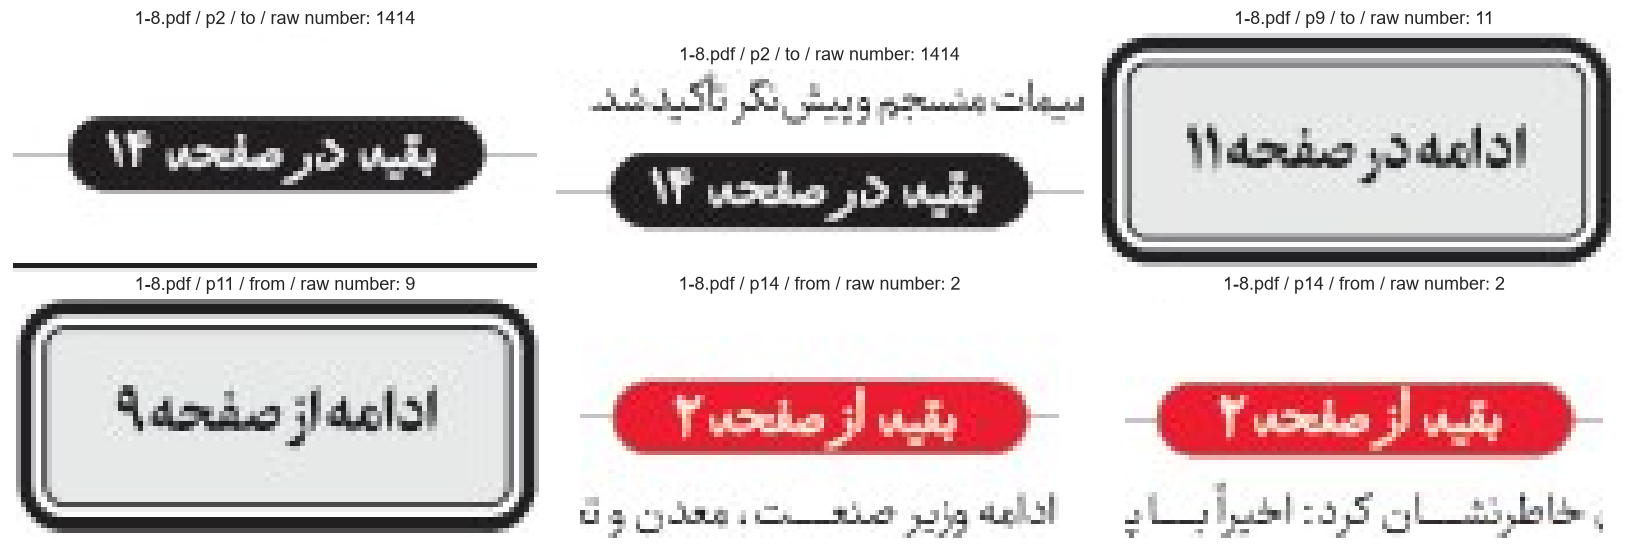

In [8]:
# Show exact marker crops. Persian is rendered from the PDF image, avoiding plotting-font/BiDi problems.
selected = markers.head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 5), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, (_, marker) in zip(axes.flat, selected.iterrows()):
    file, number = marker['file'], int(marker['pdf_page'])
    page_row = pages.loc[(pages['file'] == file) & (pages['pdf_page'] == number)].iloc[0]
    image_path = directories[file] / f'page-{number:03d}' / 'page.jpg'
    if image_path.exists() and page_row['rotation'] == 0:
        with Image.open(image_path) as image:
            sx, sy = image.width / page_row['width_pt'], image.height / page_row['height_pt']
            x0, y0, x1, y1 = marker['bbox_pdf_pt']
            crop = image.crop((max(0, int(x0*sx)-20), max(0, int(y0*sy)-15),
                               min(image.width, int(x1*sx)+20), min(image.height, int(y1*sy)+15)))
            ax.imshow(crop)
    ax.set_title(f"{file} / p{number} / {marker['direction']} / raw number: {marker['page_token']}")
plt.tight_layout()
plt.show()

### Why page-number matching alone is insufficient

The example below is **conditional**: assume a reviewer confirms printed pages 2 and 14 and resolves the duplicated `1414` tokens to 14. It illustrates ambiguity; it does not confirm article links or modify the exports.

In [9]:
outgoing = markers.loc[(markers['file'] == '1-8.pdf') & (markers['pdf_page'] == 2) & (markers['direction'] == 'to')]
incoming = markers.loc[(markers['file'] == '1-8.pdf') & (markers['pdf_page'] == 14) & (markers['direction'] == 'from')]
hypothetical_pairs = pd.DataFrame([
    {'source_marker': a, 'target_marker': b, 'status': 'Illustrative candidate, not an accepted link'}
    for a, b in itertools.product(outgoing['marker_id'], incoming['marker_id'])])
display(hypothetical_pairs)
display(Markdown(f'''**Conditional ambiguity:** {len(outgoing)} source markers × {len(incoming)} target markers
produce {len(hypothetical_pairs)} page-compatible candidate edges. Page references do not identify the correct pair.
Add title/entity overlap, local article membership and boundary-text continuity; enforce one-to-one fragment assignment and permit unresolved cases.'''))

,source_marker,target_marker,status
0,1-8-4ddf204f-p002-b0054-m000,1-8-4ddf204f-p014-b0125-m000,"Illustrative candidate, not an accepted link"
1,1-8-4ddf204f-p002-b0054-m000,1-8-4ddf204f-p014-b0130-m001,"Illustrative candidate, not an accepted link"
2,1-8-4ddf204f-p002-b0061-m001,1-8-4ddf204f-p014-b0125-m000,"Illustrative candidate, not an accepted link"
3,1-8-4ddf204f-p002-b0061-m001,1-8-4ddf204f-p014-b0130-m001,"Illustrative candidate, not an accepted link"


**Conditional ambiguity:** 2 source markers × 2 target markers
produce 4 page-compatible candidate edges. Page references do not identify the correct pair.
Add title/entity overlap, local article membership and boundary-text continuity; enforce one-to-one fragment assignment and permit unresolved cases.

### Negative control: pages 9 ↔ 11

Markers also occur in regions visually associated with classified advertisements in `1-8.pdf` pages 9 and 11. These pages should be an explicit negative-control case for the editorial stitching pipeline.

**Solution hypothesis:** classify region type before using continuation markers as editorial evidence. A reciprocal page reference is insufficient to override an advertisement/classified label. Confirm those region labels during annotation.

## 8. Raw block geometry and typography

These distributions help design a baseline and select annotation examples. They do not establish semantic roles: a large font can be a headline, an advertisement or a masthead.

Bounding boxes can extend slightly beyond the page. We count such cases as diagnostics instead of deleting their content.

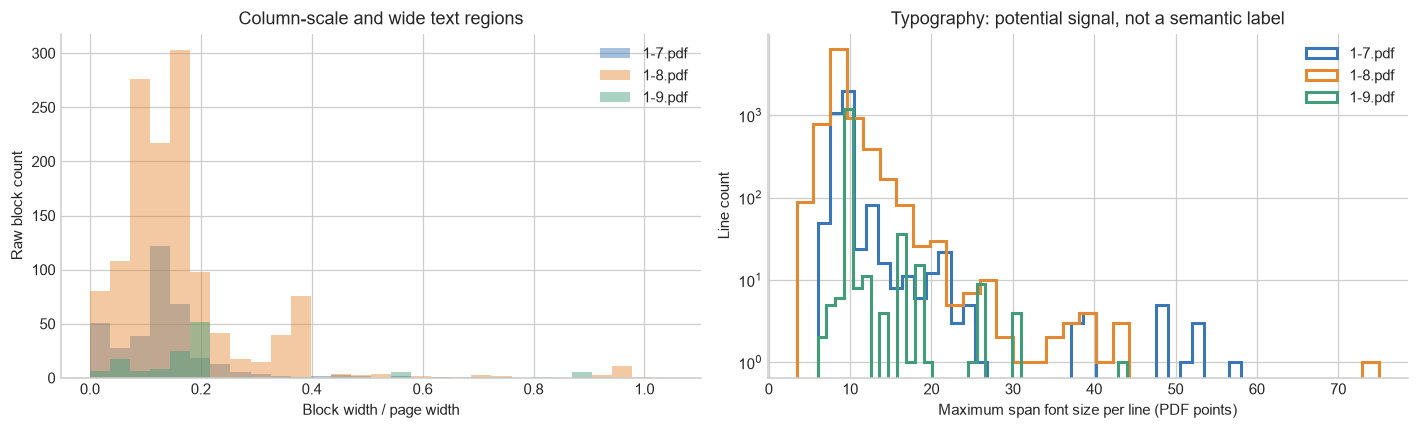

,blocks,outside_page,median_block_width,median_lines_per_block
file,,,,
1-7.pdf,362,0,0.126,4.0
1-8.pdf,1309,63,0.143,4.0
1-9.pdf,131,0,0.184,2.0


,font,size_pt,characters,file
133,Ettelaat,9.50,97687,1-8.pdf
577,BZar,10.00,64174,1-9.pdf
0,IranshahrAlpha-Text,9.00,37270,1-7.pdf
134,Ettelaat,9.31,31454,1-8.pdf
135,Ettelaat,8.00,20379,1-8.pdf
1,IranshahrAlpha-Text,8.86,15669,1-7.pdf
136,Ettelaat,9.21,14275,1-8.pdf
2,IranshahrAlpha-Text,9.18,11557,1-7.pdf
3,IranshahrAlpha-Text,8.95,8811,1-7.pdf
578,BTitrBold,16.00,856,1-9.pdf


In [10]:
block_records, line_records = [], []
for file, directory in directories.items():
    for number in pages.loc[pages['file'] == file, 'pdf_page']:
        pdir = directory / f'page-{number:03d}'
        for block in load_json(pdir / 'blocks.json'):
            x0, y0, x1, y1 = block['bbox_pdf_pt']
            page_row = pages.loc[(pages['file'] == file) & (pages['pdf_page'] == number)].iloc[0]
            block_records.append({'file': file, 'pdf_page': number, 'block_id': block['block_id'],
                                  'width_fraction': (x1-x0)/page_row['width_pt'],
                                  'height_fraction': (y1-y0)/page_row['height_pt'],
                                  'characters': len(block['text_raw']), 'line_count': block['line_count'],
                                  'extends_outside_page': x0 < 0 or y0 < 0 or x1 > page_row['width_pt'] or y1 > page_row['height_pt']})
        for line in load_json(pdir / 'lines.json'):
            line_records.append({'file': file, 'pdf_page': number, 'font_size_max': line['font_size_max'],
                                 'characters': len(line['text_raw'])})
blocks = pd.DataFrame(block_records)
lines = pd.DataFrame(line_records)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for file, group in blocks.groupby('file'):
    axes[0].hist(group['width_fraction'], bins=np.linspace(0, 1.05, 30), alpha=.45, label=file, color=COLORS[file])
for file, group in lines.groupby('file'):
    axes[1].hist(group['font_size_max'], bins=35, histtype='step', lw=2, label=file, color=COLORS[file])
axes[0].set(xlabel='Block width / page width', ylabel='Raw block count', title='Column-scale and wide text regions')
axes[1].set(xlabel='Maximum span font size per line (PDF points)', ylabel='Line count',
            title='Typography: potential signal, not a semantic label', yscale='log')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
display(blocks.groupby('file').agg(blocks=('block_id', 'count'),
                                  outside_page=('extends_outside_page', 'sum'),
                                  median_block_width=('width_fraction', 'median'),
                                  median_lines_per_block=('line_count', 'median')).round(3))
display(fonts.sort_values('characters', ascending=False).groupby('file', sort=False).head(4))

## 9. Metadata traps: printed page and publication date

The PDF page index is a file position, not necessarily a printed page number. Border numbers may be issue numbers, dates, navigation references or unrelated content.

Numeric dates in body text may be event or advertisement dates. The issue's publication date should come from a reviewed masthead or trusted archive metadata, with its source recorded.

In [11]:
metadata_checks = pages[['file', 'pdf_page', 'printed_page_candidates', 'numeric_date_candidates']].copy()
metadata_checks['candidate_page_numbers'] = metadata_checks['printed_page_candidates'].map(lambda xs: [x['number'] for x in xs])
metadata_checks['distinct_numeric_dates'] = metadata_checks['numeric_date_candidates'].map(lambda xs: sorted(set(xs)))
metadata_checks['distinct_date_count'] = metadata_checks['distinct_numeric_dates'].map(len)
display(metadata_checks.sort_values('distinct_date_count', ascending=False).head(6)[
    ['file', 'pdf_page', 'candidate_page_numbers', 'distinct_date_count', 'distinct_numeric_dates']])
display(Markdown(f'''**Measured insight:** {int((metadata_checks['distinct_date_count'] > 1).sum())}/{len(pages)} pages contain more than one distinct numeric date candidate.
Selecting the first date in extracted text is therefore not a reliable metadata strategy.
**Proposed solution:** store `pdf_page_index` separately from `printed_page_number`, and record the evidence source for publication date and newspaper name.'''))

,file,pdf_page,candidate_page_numbers,distinct_date_count,distinct_numeric_dates
8,1-8.pdf,1,"[2, 7]",17,"[1405/03/31, 1405/06/23, 1405/07/12, 1405/07/13, 1405/07/15, 1405/07/18, 1405/07/19, 1..."
18,1-8.pdf,11,[],17,"[1404/02/20, 1404/12/29, 1405/03/31, 1405/05/10, 1405/05/31, 1405/07/12, 1405/07/13, 1..."
22,1-8.pdf,15,[],17,"[1404/12/29, 1405/07/ 25, 1405/07/11, 1405/07/12, 1405/07/13, 1405/07/16, 1405/07/18, ..."
14,1-8.pdf,7,"[7, 6]",15,"[1404/12/29, 1405/05 -02, 1405/07/07, 1405/07/12, 1405/07/13, 1405/07/15, 1405/07/16, ..."
15,1-8.pdf,8,[],14,"[1404/12/29, 1405/02/05, 1405/05/18, 1405/07/09, 1405/07/10, 1405/07/11, 1405/07/12, 1..."
21,1-8.pdf,14,"[14, 89, 83, 95, 91, 43, 68, 150]",14,"[1404/7/28, 1405/ 8/18, 1405/07 /19, 1405/07 /25, 1405/07/08, 1405/07/09, 1405/07/13, ..."


**Measured insight:** 13/28 pages contain more than one distinct numeric date candidate.
Selecting the first date in extracted text is therefore not a reliable metadata strategy.
**Proposed solution:** store `pdf_page_index` separately from `printed_page_number`, and record the evidence source for publication date and newspaper name.

## 10. Runtime and memory — what was timed, and what was not?

Measured EDA time includes PDF inspection, page image rendering, sample crops and page exports. It excludes OCR, semantic layout detection, article grouping and stitching. File hashing and final reports are outside the reported inspection/export total.

The recorded runs are sequential, single-worker exploratory runs, not repeated controlled benchmarks. The reference deployment CPU is not established. RSS is sampled every 50 ms and can miss short peaks; later files also inherit process-level allocations from earlier files.

,file,page_count,inspection_export_wall_seconds,page_seconds_p50,page_seconds_p95,sampled_process_tree_peak_rss_mb,eda_seconds_per_page
0,1-7.pdf,8,17.30,2.07,2.48,179.55,2.16
1,1-8.pdf,16,36.25,2.04,3.53,290.40,2.27
2,1-9.pdf,4,5.99,1.47,1.72,346.46,1.50


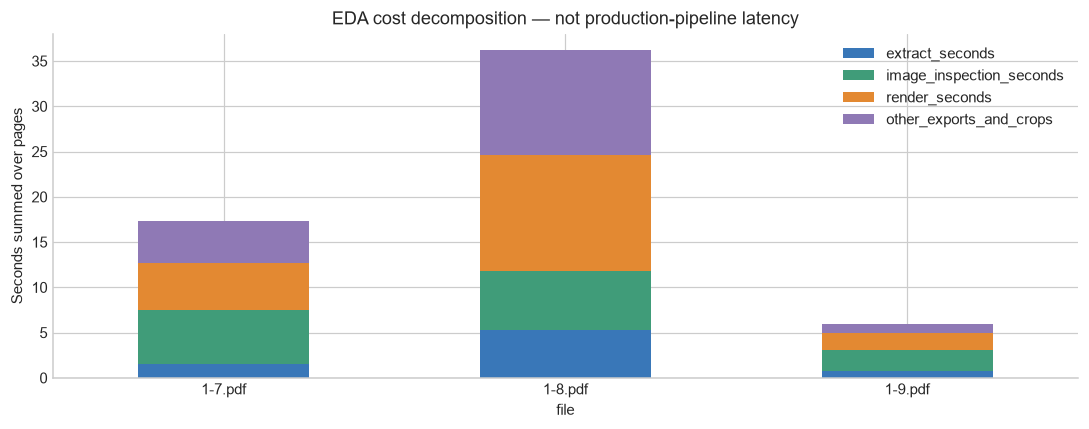

,issue_pages,120s_budget_per_page,180s_budget_per_page
0,16,7.5,11.25
1,24,5.0,7.50


**Interpretation:** these are issue-level wall-time shares, not permitted per-worker page latencies. EDA speed cannot establish the final CPU budget. Measure OCR, layout, stitching, startup and I/O end-to-end on the designated reference machine.

In [12]:
runtime = inventory[['file', 'page_count', 'inspection_export_wall_seconds', 'page_seconds_p50',
                     'page_seconds_p95', 'sampled_process_tree_peak_rss_mb']].copy()
runtime['eda_seconds_per_page'] = runtime['inspection_export_wall_seconds'] / runtime['page_count']
display(runtime.round(2))

components = pages.groupby('file')[['extract_seconds', 'image_inspection_seconds', 'render_seconds']].sum()
page_totals = pages.groupby('file')['page_wall_seconds_including_exports'].sum()
components['other_exports_and_crops'] = (page_totals - components.sum(axis=1)).clip(lower=0)
components.plot.bar(stacked=True, figsize=(10, 4), color=['#3977b8', '#409c79', '#e38932', '#8f79b5'])
plt.ylabel('Seconds summed over pages')
plt.title('EDA cost decomposition — not production-pipeline latency')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

budget = pd.DataFrame({'issue_pages': [16, 24], '120s_budget_per_page': [120/16, 120/24],
                       '180s_budget_per_page': [180/16, 180/24]})
display(budget)
display(Markdown('**Interpretation:** these are issue-level wall-time shares, not permitted per-worker page latencies. EDA speed cannot establish the final CPU budget. Measure OCR, layout, stitching, startup and I/O end-to-end on the designated reference machine.'))

## 11. Human validation: make text accuracy measurable

The exporter samples up to five eligible lines per page (minimum 15 characters), with a fixed random seed. This is a convenience sample of **extractable lines**, not a complete audit of missing text or a representative sample of all archive scans.

1. Hide the prediction column and transcribe from the crop.
2. Fill `reference` and set `reviewed=1` in a copy of `annotation-lines.csv`.
3. Use the same reference for PDF text, Tesseract and PaddleOCR predictions.
4. Add targeted hard lines and missing-text regions; report random and hard strata separately.
5. Split train/validation/test by complete issue, never by individual pages of the same issue.

Run `python eda.py cer <reviewed.csv> --output cer.json`.

Report strict CER and normalized CER (NFC, yeh/kaf and digit-shape mapping; whitespace and ZWNJ retained). Do not treat OCR confidence as CER.

,sampled_lines,reviewed_lines
file,,
1-7.pdf,40,0
1-8.pdf,80,0
1-9.pdf,20,0


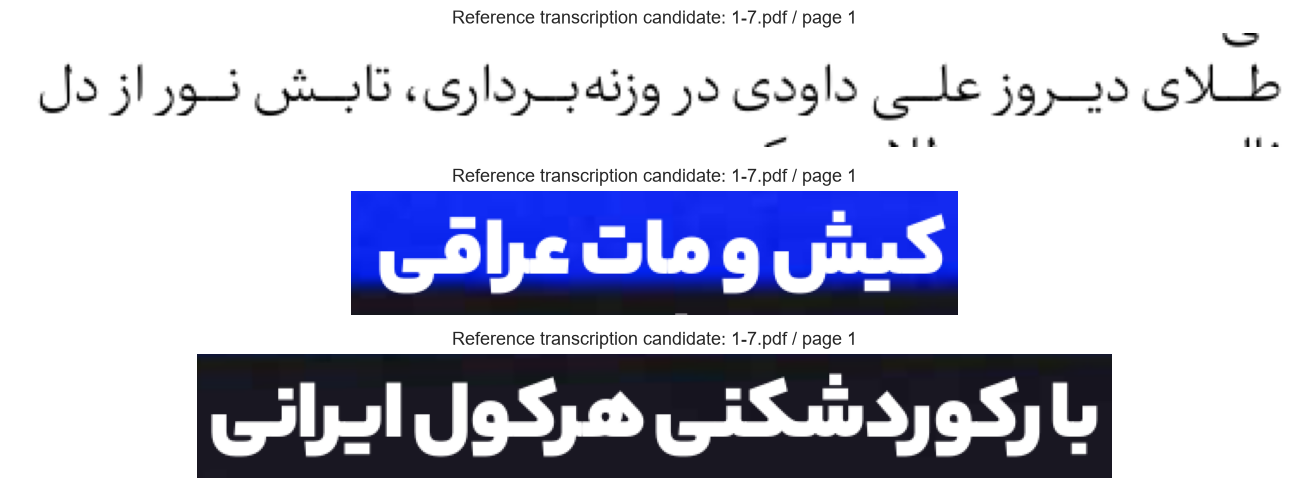

**Accuracy status:** no human-reviewed CER results supplied; text accuracy remains unmeasured. Layout IoU and exact-article stitching accuracy are also unavailable.

In [13]:
annotations = read_issue_table('annotation-lines.csv')
annotations['is_reviewed'] = annotations['reviewed'].fillna('').astype(str).str.lower().isin(['1', '1.0', 'true', 'yes'])
display(annotations.groupby('file').agg(sampled_lines=('line_id', 'count'),
                                       reviewed_lines=('is_reviewed', 'sum')))

sample = annotations.loc[annotations['image_path'].notna()].head(3)
fig, axes = plt.subplots(3, 1, figsize=(12, 4.5))
for ax, (_, row) in zip(axes, sample.iterrows()):
    path = directories[row['file']] / row['image_path']
    if path.exists():
        with Image.open(path) as image:
            ax.imshow(image.copy())
    ax.set_title(f"Reference transcription candidate: {row['file']} / page {row['pdf_page']}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# Load real CER results only if explicitly supplied. No simulated accuracy is plotted.
CER_RESULTS = None  # Example: Path('cer.json') after human transcription.
if CER_RESULTS is not None:
    display(load_json(Path(CER_RESULTS)))
else:
    display(Markdown('**Accuracy status:** no human-reviewed CER results supplied; text accuracy remains unmeasured. Layout IoU and exact-article stitching accuracy are also unavailable.'))

## 12. Evidence → insight → proposed action

| Evidence from this sample | Defensible insight | Proposed action | What would validate it? |
|---|---|---|---|
| All 28 pages contain extractable text | PDF-first is a credible baseline for these files | Preserve spans/bboxes; OCR only missing or demonstrably bad regions | Human CER for PDF text; coverage audit against page images |
| Text/image composition and raw block counts vary | A uniform page policy may waste work and hide hard cases | Stratify pages and use region-level routing | Per-stratum layout, grouping, OCR and runtime results |
| `1414` occurs in continuation extraction | Clean Unicode does not imply correct numbers | Span-aware parsing, raw evidence, explicit candidate/review state | Reviewed marker precision/recall and number accuracy |
| Multiple 2 → 14 and 14 ← 2 markers | Page-number matching is ambiguous | Constrained fragment graph with title/entities and boundary continuity | Exact ordered fragment match; false-merge rate |
| Markers exist near classified content on 9/11 | Continuation is not necessarily editorial | Content-type gating before editorial stitching | Advertisement leakage rate and negative-control cases |
| Multiple numeric dates occur on some pages | First-date extraction is unreliable | Masthead/metadata-specific evidence and reviewed page mapping | Metadata accuracy against human issue labels |
| No demonstrated text-free scan in the sample | Scanned-archive generalization is not established | Obtain real scanned-only issues early | OCR CER/runtime across scan quality and newspaper/time periods |
| No gold articles, layout or OCR transcripts | Final quality is not yet measurable | Build a small issue-level gold set before tuning | Reproducible held-out metrics and an error taxonomy |

## 13. Three candidate solutions

### A. PDF-first geometric baseline — best first implementation for this sample

**Pipeline:** PDF spans/lines → column and separator geometry → local headline/body grouping → RTL order within each fragment → marker extraction → conservative links → provenance-rich JSON.

**Tools:** PyMuPDF, OpenCV, character TF-IDF and a lightweight pairwise scorer; JSON/SQLite outputs. Use Tesseract `fas` as the initial OCR fallback.

**Strength:** reuses available text and geometry; cheap and inspectable.
**Risk:** malformed PDF text, complex wrapping and semantic advertisement boundaries.
**Decision gate:** keep it as the default if human text accuracy is acceptable and targeted layout errors are limited. Resolve the PyMuPDF AGPL/commercial license choice for deployment.

### B. Hybrid selective OCR + conditional detector — proposed production direction

**Pipeline:** region-level text validation → preserve good PDF text → OCR bad/missing regions → detector only where the geometric baseline fails → common fragment graph.

**Candidates to compare:** Tesseract `fas` versus PaddleOCR's documented Persian-capable Arabic-family recognizer; geometry versus DocLayout-YOLO on the same labeled pages. Check exact model versions and artifact licenses before adoption.

**Strength:** targets compute at difficult regions instead of the whole issue.
**Risk:** routing can miss text, and detector overhead can erase savings.
**Decision gate:** adopt only if end-to-end accuracy improves at acceptable CPU cost. Evaluate routing recall, not just the accuracy of selected crops.

### C. Scanned-only path — necessary stress test, not proven by this corpus

**Pipeline:** native scan/raster input → mild deskew/contrast → low-resolution layout → high-resolution block/line OCR → common fragment graph.

**Strength:** handles archive pages with no usable PDF text.
**Risk:** dense Persian text may exceed the 180-second issue budget on CPU.
**Decision gate:** benchmark a real 16/24-page scanned issue on the reference CPU. After profiling, compare native/ONNX/OpenVINO and FP32/INT8 for the selected model. Quantization is an experiment, not a guaranteed speedup. VLM use requires a separately demonstrated bounded latency and accuracy benefit.

## 14. Proposed stitching design

The graph node should be a **locally ordered article fragment**, not a whole page or raw PDF block.

```text
Page + raw blocks + semantic region labels
    → local article fragments and RTL order
    → bounded candidate continuations
    → pairwise evidence score
    → constrained path assignment
    → complete / incomplete / unresolved article + provenance
```

**Candidate evidence:** reviewed printed-page references, title/short-title similarity, named entities and numbers, local geometry, boundary-text continuity and extraction confidence. Small multilingual embeddings can be an optional feature; topic similarity alone should never determine a link.

**Constraints:** each fragment belongs to at most one article; at most one incoming and outgoing continuation in the baseline chain model; no self-links or cycles; editorial compatibility; unmatched fragments allowed. Complex branching article structures should be identified during annotation and modeled explicitly if present.

**Uncertainty:** use a score threshold and a margin over competing assignments; retain candidates and rejection reasons. Do not claim an unresolved article is complete.

**Text integrity:** keep raw extraction; remove continuation notices from article text only with recorded provenance; repair broken boundary words only after accepting the link, with a reversible edit log.

## 15. Prioritized experiments and evaluation plan

| Priority | Experiment | Measure | Decision it unlocks |
|---|---|---|---|
| P0 | PDF text vs human transcripts; include duplicated-number examples | Strict/normalized CER, missing-text and duplicate-text rates | Can the text layer be the default? |
| P0 | Acquire a genuinely scanned-only issue | End-to-end OCR time, RAM, text accuracy | Is the CPU requirement feasible for the intended archive? |
| P1 | Geometry vs detector on identical labeled strata | Per-class IoU/mAP, title recall, advertisement leakage, grouping errors | Where does the detector justify its overhead? |
| P1 | Marker/page baseline vs title/entity/continuity features | Exact ordered article reconstruction, edge precision/recall, false merges, unresolved rate | Does added complexity improve stitching? |
| P1 | Tesseract vs PaddleOCR on identical crops and references | CER by font size/scan quality; total detector + recognizer time | Which OCR engine fits the actual data? |
| P2 | Add small embeddings to bounded candidates | Held-out exact-article improvement and latency | Are semantic features worth the cost? |
| P2 | Native vs optimized backend; FP32 vs INT8 | Full-issue time, model size, process-tree RSS, accuracy change | Does model compression improve the real trade-off? |

**Ground-truth schema:** region type, article/fragment IDs, bbox, reading order, continuation from/to, printed page, uncertainty and selected line transcripts.

**Core stitching metric:** percentage of reference articles recovered with exactly all fragments in the correct order. Also report false merges and falsely claimed completeness; edge accuracy alone can hide incomplete articles.

**Benchmark protocol:** one startup run, three warm runs; record cold startup separately; fixed input checksums, versions, DPI and thread/worker settings. Measure full issue wall time and process-tree RAM on the designated CPU. Split by complete issue and reserve a newspaper/time-period holdout if available.

## 16. Six-week MVP delivery outline

| Week | Deliverable | Evidence required before progressing |
|---|---|---|
| 1 | Reference hardware, small gold set, PDF/OCR comparison, real scan stress test | Actual CER/runtime; confirmed printed-page mapping |
| 2 | Ingestion, provenance, geometry baseline and reviewed overlays | No output block without source coordinates |
| 3 | Local article grouping and RTL order; targeted detector trial if justified | Grouping/order errors and advertisement leakage by page stratum |
| 4 | Marker extraction, candidate scoring, constrained stitching, unresolved state | 2 ↔ 14 ambiguity and 9 ↔ 11 negative-control results |
| 5 | Calibrate thresholds and profile/optimize CPU | Before/after full-issue time, RAM, model size and accuracy |
| 6 | Held-out issue evaluation, error fixes and reproducible delivery | Honest completeness metrics and measured CPU budget; optional search only after core readiness |

## Closing takeaway

**The observed sample favors a PDF-text-first, provenance-preserving hybrid pipeline.**

The critical engineering problem is not just character extraction: it is identifying article membership and ordering fragments without false merges. The strongest next investment is a small, diverse gold set plus a genuinely scanned-only benchmark. These will determine whether geometric rules, selective OCR and constrained stitching satisfy the requirements — and where additional models are genuinely needed.

**Claims deliberately left open:** final CER, layout accuracy, exact-article accuracy, compression gains and 180-second feasibility for scanned issues.

### Reference entry points (candidate tools; not benchmark evidence)
- [PyMuPDF documentation and licensing](https://pymupdf.readthedocs.io/en/latest/about.html)
- [Tesseract fast language models](https://github.com/tesseract-ocr/tessdata_fast)
- [PaddleOCR multilingual recognition documentation](https://github.com/PaddlePaddle/PaddleOCR/blob/main/docs/version3.x/algorithm/PP-OCRv5/PP-OCRv5_multi_languages.en.md)
- [DocLayout-YOLO](https://github.com/opendatalab/DocLayout-YOLO)
- [ONNX Runtime quantization](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html)

Tool capabilities and licenses should be verified for the exact selected code and weight artifacts. External benchmark results should not be presented as accuracy on these newspapers.